# 01. Análise Exploratória de Dados (EDA) — Vendas, Retiradas, FPD, Dias Úteis, Bairros e Canais

**Etapa CRISP-DM:** Entendimento do Negócio e Entendimento dos Dados  
**Fonte:** Data Warehouse `db_thefiber` (`fato_churn_contrato` + tabelas De-Para do `dash-retencao`)

### Objetivos deste notebook
1. Auditar a qualidade dos dados extraídos do DW e validar a separação entre **meses fechados** e **mês parcial corrente**.
2. Analisar a evolução histórica (2024–2026) de **Vendas (Ativações)**, **Retiradas (Cancelamentos totais do mês, independente da safra)**, **Saldo Líquido**, **Carteira (Planta)** e **FPD (61 dias)** — incluindo a censura à direita dos meses recentes.
3. Investigar **anomalias de retiradas** (baixas em lote no IXC) que poderiam distorcer uma Regressão Linear.
4. Validar empiricamente a regra de negócio de **Dias Úteis Ponderados (`1,0` útil / `0,5` sábado / `0,0` domingo e feriado)** usando a série diária real.
5. Realizar análise exploratória estratégica sobre **Novos Bairros (curva de ramp-up por Tipo de Rede)** e **Novos Canais de Venda** para embasar as variáveis do modelo e os cenários de 2027.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()
DATA_RAW = ROOT / "data" / "raw"
DATA_PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

with open(DATA_RAW / "extract_metadata.json", encoding="utf-8") as f:
    ext_meta = json.load(f)
with open(DATA_PROC / "features_metadata.json", encoding="utf-8") as f:
    feat_meta = json.load(f)

df_mensal = pd.read_parquet(DATA_PROC / "serie_mensal_ml.parquet")
df_closed = df_mensal[df_mensal["mes_fechado"]].copy()
df_diaria = pd.read_parquet(DATA_PROC / "serie_diaria.parquet")
df_pesos = pd.read_parquet(DATA_PROC / "pesos_empiricos_dias.parquet")
df_bairros = pd.read_parquet(DATA_PROC / "analise_bairros.parquet")
df_canais = pd.read_parquet(DATA_PROC / "analise_canais.parquet")

print("=== AUDITORIA DA EXTRAÇÃO (DW -> PARQUET) ===")
print(f"Contratos extraídos (desduplicados): {ext_meta['rows_deduplicated']:,}")
print(f"Período completo no DW: {ext_meta['min_anomes_ativacao']} até {ext_meta['max_anomes_ativacao']}")
print(f"Última data de ativação: {ext_meta['max_data_ativacao']} | Cancelamento: {ext_meta['max_data_cancelamento']}")
print(f"Último mês fechado considerado para ML: {feat_meta['last_closed_month']} ({feat_meta['closed_months_count']} meses fechados)")
print(f"Carteira base (Dez/2023): {feat_meta['carteira_inicial_2023_12']:,} -> Carteira atual ({feat_meta['last_closed_month']}): {feat_meta['carteira_ultimo_mes_fechado']:,}")


=== AUDITORIA DA EXTRAÇÃO (DW -> PARQUET) ===
Contratos extraídos (desduplicados): 69,478
Período completo no DW: 2014-03 até 2026-11
Última data de ativação: 2026-11-23 | Cancelamento: 2026-11-23
Último mês fechado considerado para ML: 2026-10 (34 meses fechados)
Carteira base (Dez/2023): 14,082 -> Carteira atual (2026-10): 33,755


## 1. Série Histórica: Vendas, Retiradas, Saldo Líquido e Carteira (2024–2026)

Abaixo visualizamos a dinâmica mensal nos meses fechados, destacando automaticamente:
- A forte aceleração comercial a partir de 2025;
- Os **dois picos atípicos de retiradas (`2025-06` e `2025-08`)**, característicos de baixa em lote de inadimplência acumulada no IXC;
- A diferença entre **volume bruto de vendas** e **vendas por dia útil ponderado** (explicando imediatamente quedas de calendário como Fevereiro/2026 e picos como Julho/2026).

,ano,meses,du_ponderados,vendas,retiradas,inadimplencia,voluntario,saldo_liquido,carteira_fim,bairros_ativos_media,canais_ativos_media,vendas_por_du,retirada_sobre_venda_pct
0,2024,12,274.5,5393,2460,314,2132,2933,17015,117.3,4.6,19.6,45.6
1,2025,12,275.5,12042,5974,1977,3990,6068,23083,182.0,6.8,43.7,49.6
2,2026,10,229.5,18547,7875,5195,2680,10672,33755,287.5,8.3,80.8,42.5


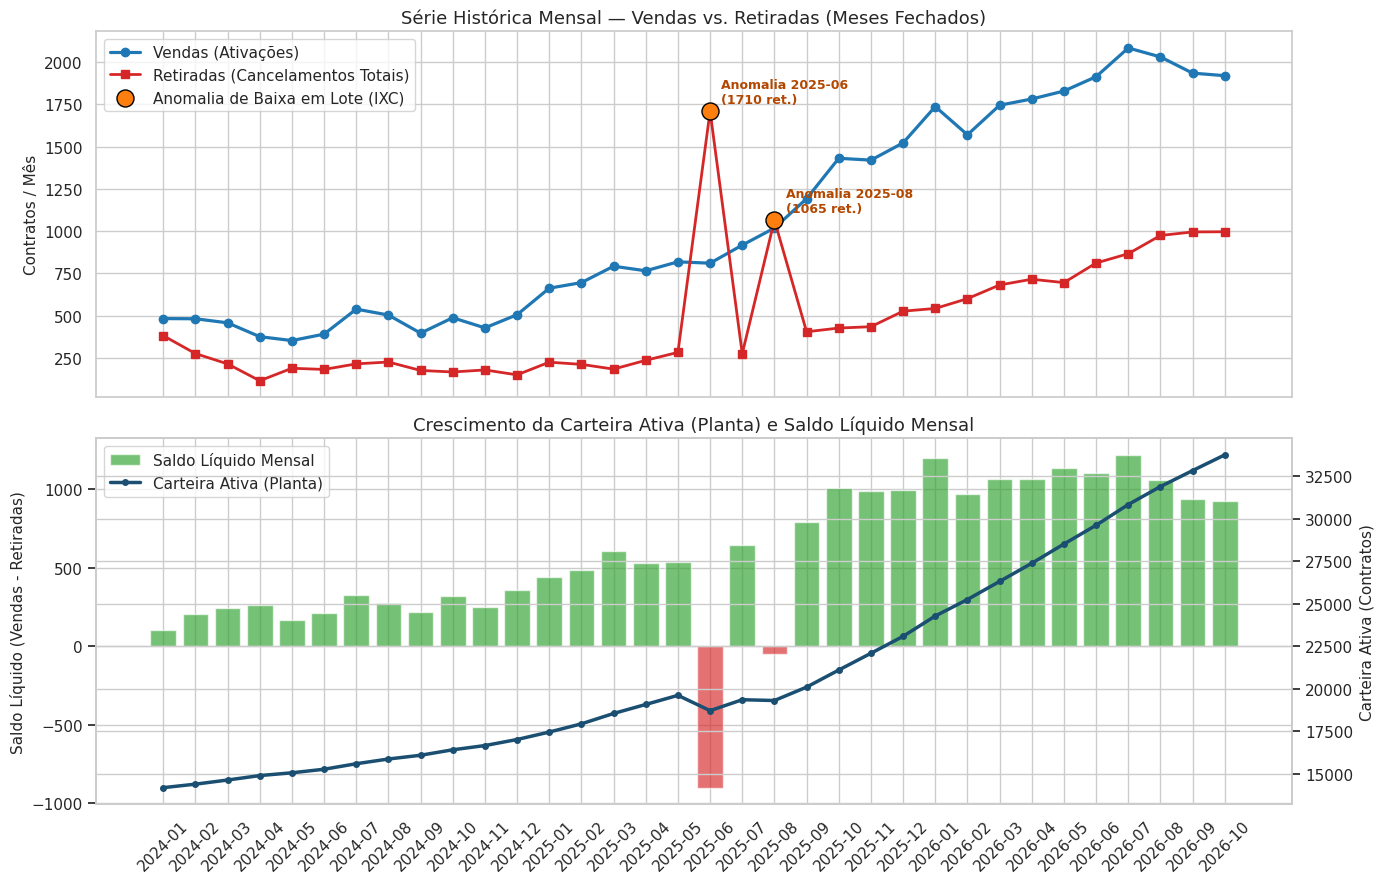

In [2]:
resumo_anual = (
    df_closed.groupby("ano", as_index=False)
    .agg(
        meses=("anomes", "count"),
        du_ponderados=("dias_uteis_ponderados", "sum"),
        vendas=("vendas", "sum"),
        retiradas=("retiradas", "sum"),
        inadimplencia=("retiradas_inadimplencia", "sum"),
        voluntario=("retiradas_voluntario", "sum"),
        saldo_liquido=("saldo_liquido", "sum"),
        carteira_fim=("carteira_fim_mes", "last"),
        bairros_ativos_media=("qtd_bairros_ativos_mes", "mean"),
        canais_ativos_media=("qtd_canais_ativos_mes", "mean"),
    )
)
resumo_anual["vendas_por_du"] = (resumo_anual["vendas"] / resumo_anual["du_ponderados"]).round(2)
resumo_anual["retirada_sobre_venda_pct"] = (resumo_anual["retiradas"] / resumo_anual["vendas"] * 100).round(1)
display(resumo_anual.round(1))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Painel 1: Vendas vs Retiradas com destaque de anomalias
ax = axes[0]
ax.plot(df_closed["anomes"], df_closed["vendas"], marker="o", lw=2.3, color="#1f77b4", label="Vendas (Ativações)")
ax.plot(df_closed["anomes"], df_closed["retiradas"], marker="s", lw=2.0, color="#d62728", label="Retiradas (Cancelamentos Totais)")
anom = df_closed[df_closed["anomalia_retirada"] == 1]
ax.scatter(anom["anomes"], anom["retiradas"], s=150, color="#ff7f0e", edgecolor="black", zorder=5, label="Anomalia de Baixa em Lote (IXC)")
for _, r in anom.iterrows():
    ax.annotate(f"Anomalia {r['anomes']}\n({r['retiradas']} ret.)", (r["anomes"], r["retiradas"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9, fontweight="bold", color="#b34700")
ax.set_title("Série Histórica Mensal — Vendas vs. Retiradas (Meses Fechados)")
ax.set_ylabel("Contratos / Mês")
ax.legend(loc="upper left")

# Painel 2: Evolução da Carteira (Planta) e Saldo Líquido
ax2 = axes[1]
bars = ax2.bar(df_closed["anomes"], df_closed["saldo_liquido"],
               color=np.where(df_closed["saldo_liquido"] >= 0, "#2ca02c", "#d62728"), alpha=0.65, label="Saldo Líquido Mensal")
ax2.set_ylabel("Saldo Líquido (Vendas - Retiradas)")
ax2_r = ax2.twinx()
ax2_r.plot(df_closed["anomes"], df_closed["carteira_fim_mes"], color="#1b4f72", lw=2.5, marker="o", markersize=4, label="Carteira Ativa (Planta)")
ax2_r.set_ylabel("Carteira Ativa (Contratos)")
ax2.set_title("Crescimento da Carteira Ativa (Planta) e Saldo Líquido Mensal")
ax2.tick_params(axis="x", rotation=45)

h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2_r.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_serie_historica_vendas_retiradas_planta.png", dpi=140)
plt.show()


## 2. Validação Empírica dos Pesos de Dias Úteis (`1,0` / `0,5` / `0,0`)

Comparamos a regra operacional adotada (`Dia Útil = 1,0`, `Sábado = 0,5`, `Domingo/Feriado = 0,0`) com a média empírica diária de ativações e retiradas registrada no DW de Jan/2024 a Out/2026.

Também verificamos como normalizar vendas por **dias úteis ponderados (`vendas / DU`)** elimina o ruído de calendário (ex.: Fev/2026 com apenas `20,0 DU` por causa do Carnaval vs. Jul/2026 com `25,0 DU`).

,tipo_dia,qtd_dias,media_vendas,media_retiradas,peso_teorico,peso_empirico_vendas,peso_empirico_retiradas
0,Dia Útil,709,42.464,19.828,1.0,1.000,1.000
1,Sábado,141,31.624,14.149,0.5,0.745,0.714
2,Domingo,141,4.518,0.028,0.0,0.106,0.001
3,Feriado,44,17.705,5.727,0.0,0.417,0.289


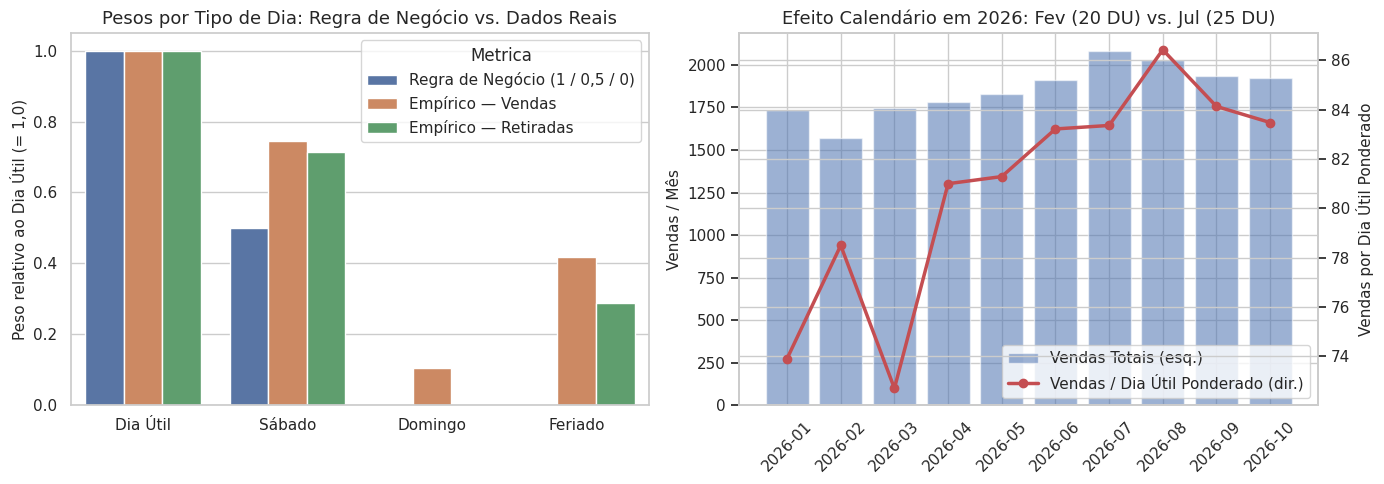

In [3]:
display(df_pesos.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Peso teórico vs empírico
df_melt = df_pesos.melt(
    id_vars="tipo_dia",
    value_vars=["peso_teorico", "peso_empirico_vendas", "peso_empirico_retiradas"],
    var_name="Metrica",
    value_name="Peso",
)
df_melt["Metrica"] = df_melt["Metrica"].map({
    "peso_teorico": "Regra de Negócio (1 / 0,5 / 0)",
    "peso_empirico_vendas": "Empírico — Vendas",
    "peso_empirico_retiradas": "Empírico — Retiradas",
})
sns.barplot(data=df_melt, x="tipo_dia", y="Peso", hue="Metrica", ax=axes[0])
axes[0].set_title("Pesos por Tipo de Dia: Regra de Negócio vs. Dados Reais")
axes[0].set_xlabel("")
axes[0].set_ylabel("Peso relativo ao Dia Útil (= 1,0)")

# Gráfico 2: Efeito do calendário em 2026 (Volume bruto vs Vendas por DU)
df_2026 = df_closed[df_closed["ano"] == 2026].copy()
ax_l = axes[1]
ax_l.bar(df_2026["anomes"], df_2026["vendas"], alpha=0.55, color="#4c72b0", label="Vendas Totais (esq.)")
ax_l.set_ylabel("Vendas / Mês")
ax_l.tick_params(axis="x", rotation=45)
ax_r = ax_l.twinx()
ax_r.plot(df_2026["anomes"], df_2026["vendas_por_du"], color="#c44e52", lw=2.5, marker="o", label="Vendas / Dia Útil Ponderado (dir.)")
ax_r.set_ylabel("Vendas por Dia Útil Ponderado")
ax_l.set_title("Efeito Calendário em 2026: Fev (20 DU) vs. Jul (25 DU)")
h1, l1 = ax_l.get_legend_handles_labels()
h2, l2 = ax_r.get_legend_handles_labels()
ax_l.legend(h1 + h2, l1 + l2, loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_validacao_dias_uteis.png", dpi=140)
plt.show()


## 3. Qualidade das Vendas (FPD 61 dias) e Composição das Retiradas

- **Atenção à censura à direita no FPD**: contratos ativados nos últimos ~2 a 3 meses ainda não completaram 61 dias após o vencimento da 1ª fatura; por isso o indicador cai artificialmente próximo do presente. O pipeline marca automaticamente `fpd_maturado = True` apenas até o mês de corte seguro.
- **Composição das retiradas**: separar *Inadimplência* vs. *Cancelamento Voluntário* comprova visualmente que os picos de `2025-06` e `2025-08` foram choques pontuais de baixa de inadimplência.

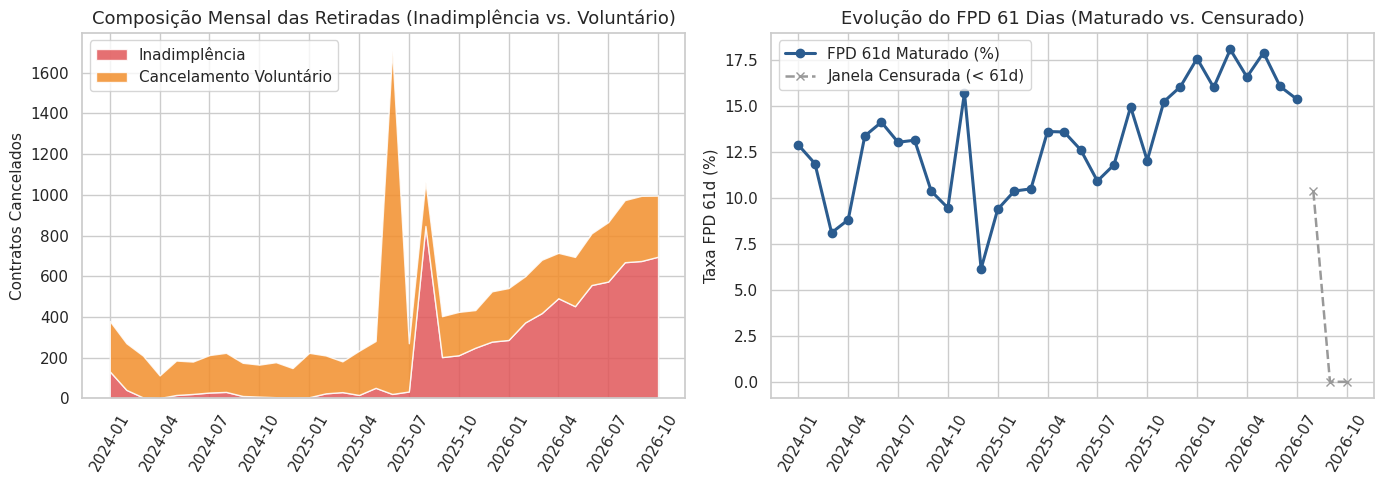

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Composição das Retiradas
axes[0].stackplot(
    df_closed["anomes"],
    df_closed["retiradas_inadimplencia"],
    df_closed["retiradas_voluntario"],
    labels=["Inadimplência", "Cancelamento Voluntário"],
    colors=["#e15759", "#f28e2b"],
    alpha=0.85,
)
axes[0].set_title("Composição Mensal das Retiradas (Inadimplência vs. Voluntário)")
axes[0].set_ylabel("Contratos Cancelados")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_xticks(range(0, len(df_closed), 3))
axes[0].legend(loc="upper left")

# FPD 61d maturado vs censurado
mat = df_closed[df_closed["fpd_maturado"]]
cens = df_closed[~df_closed["fpd_maturado"]]
axes[1].plot(mat["anomes"], mat["taxa_fpd_61d"] * 100, marker="o", lw=2.2, color="#2b5c8f", label="FPD 61d Maturado (%)")
axes[1].plot(cens["anomes"], cens["taxa_fpd_61d"] * 100, marker="x", lw=1.8, ls="--", color="#999999", label="Janela Censurada (< 61d)")
axes[1].set_title("Evolução do FPD 61 Dias (Maturado vs. Censurado)")
axes[1].set_ylabel("Taxa FPD 61d (%)")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_xticks(range(0, len(df_closed), 3))
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_fpd_e_composicao_retiradas.png", dpi=140)
plt.show()


## 4. EDA Estratégica: Novos Bairros (Curva de Ramp-up) e Novos Canais de Venda

Esta seção investiga duas alavancas essenciais de crescimento para 2027:
1. **Novos Bairros**: quantas vendas e retiradas um bairro recém-aberto entrega entre o mês de estreia (`M0`) e o 6º mês (`M6`), comparando **Rede Própria** vs. **Rede Neutra**.
2. **Novos Canais de Venda**: o papel dos canais lançados entre fim de 2024 e 2026 (`Loja Lorena`, `Loja Vera Cruz`, `Loja Maysa`, `INDIQUE E GANHE`, `ORBI`) na mudança de patamar de vendas e qualidade (FPD).

=== CURVA DE RAMP-UP DE NOVOS BAIRROS (M0 a M6) ===


,tipo_rede_efetivo,idade_bairro_meses,bairros_ativos,media_vendas,media_retiradas
0,Rede Neutra,0,137,1.56,0.03
1,Rede Neutra,1,46,2.98,0.00
2,Rede Neutra,2,40,3.48,0.05
3,Rede Neutra,3,51,3.25,0.63
4,Rede Neutra,4,44,3.33,1.13
5,Rede Neutra,5,47,3.32,1.00
6,Rede Neutra,6,40,3.28,1.80
7,Rede Própria,0,116,1.57,0.02
8,Rede Própria,1,35,2.58,0.00
9,Rede Própria,2,29,4.59,0.07


=== DESEMPENHO POR CANAL DE VENDA (2024–2026) ===


,canal_venda_efetivo,mes_estreia_canal,meses_ativos,vendas,retiradas,fpd_61d,vendas_por_mes_ativo,taxa_fpd_pct,retirada_sobre_venda_pct
3,Loja Lorena,2024-11,24,8139,2236,855,339.1,10.5,27.5
0,Agente Autorizado,2014-03,34,7134,5659,1401,209.8,19.6,79.3
5,Loja Vera Cruz,2025-02,21,6440,1323,602,306.7,9.3,20.5
8,Quiosque,2020-03,30,3856,1879,477,128.5,12.4,48.7
9,Vendedor Interno,2020-10,33,3734,2678,449,113.2,12.0,71.7
4,Loja Maysa,2025-12,11,2087,236,182,189.7,8.7,11.3
2,INDIQUE E GANHE,2025-11,10,904,97,71,90.4,7.9,10.7
1,Condominio,2025-09,14,536,203,129,38.3,24.1,37.9
7,ORBI,2026-07,4,251,5,7,62.8,2.8,2.0
6,Mundiale,2026-04,2,24,1,3,12.0,12.5,4.2


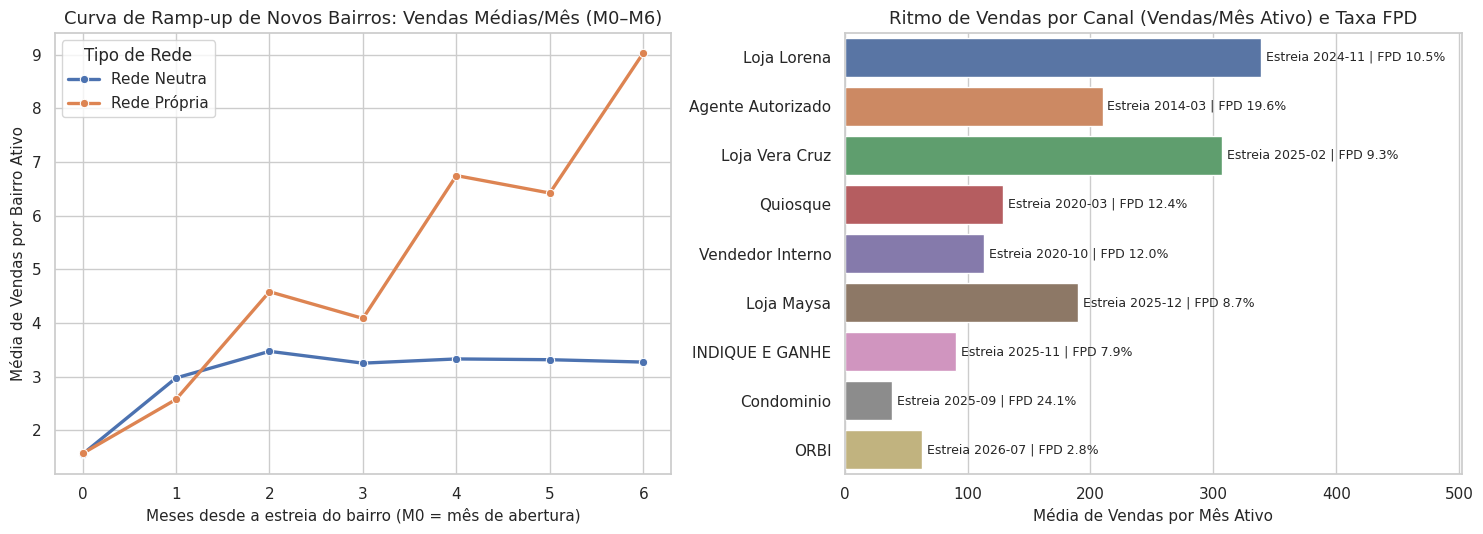

In [5]:
# 4.1 Curva de Ramp-up de Novos Bairros (abertos a partir de 2024-01)
bn = df_bairros[
    df_bairros["bairro_novo_periodo"]
    & df_bairros["tipo_rede_efetivo"].isin(["Rede Própria", "Rede Neutra"])
    & (df_bairros["idade_bairro_meses"] <= 6)
].copy()

ramp_up = (
    bn.groupby(["tipo_rede_efetivo", "idade_bairro_meses"], as_index=False)
    .agg(
        bairros_ativos=("bairro_norm", "nunique"),
        media_vendas=("vendas", "mean"),
        media_retiradas=("retiradas", "mean"),
    )
)
print("=== CURVA DE RAMP-UP DE NOVOS BAIRROS (M0 a M6) ===")
display(ramp_up.round(2))

# 4.2 Resumo por Canal de Venda
canais_resumo = (
    df_canais.groupby(["canal_venda_efetivo", "mes_estreia_canal"], as_index=False)
    .agg(
        meses_ativos=("anomes", "nunique"),
        vendas=("vendas", "sum"),
        retiradas=("retiradas", "sum"),
        fpd_61d=("fpd_61d", "sum"),
    )
    .sort_values("vendas", ascending=False)
)
canais_resumo["vendas_por_mes_ativo"] = (canais_resumo["vendas"] / canais_resumo["meses_ativos"]).round(1)
canais_resumo["taxa_fpd_pct"] = (canais_resumo["fpd_61d"] / canais_resumo["vendas"] * 100).round(1)
canais_resumo["retirada_sobre_venda_pct"] = (canais_resumo["retiradas"] / canais_resumo["vendas"] * 100).round(1)
print("=== DESEMPENHO POR CANAL DE VENDA (2024–2026) ===")
display(canais_resumo)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Gráfico Ramp-up Bairros
sns.lineplot(data=ramp_up, x="idade_bairro_meses", y="media_vendas", hue="tipo_rede_efetivo", marker="o", lw=2.4, ax=axes[0])
axes[0].set_title("Curva de Ramp-up de Novos Bairros: Vendas Médias/Mês (M0–M6)")
axes[0].set_xlabel("Meses desde a estreia do bairro (M0 = mês de abertura)")
axes[0].set_ylabel("Média de Vendas por Bairro Ativo")
axes[0].legend(title="Tipo de Rede")

# Gráfico Canais (Vendas/mês ativo vs FPD%)
top_c = canais_resumo[canais_resumo["vendas"] >= 200].copy()
sns.barplot(data=top_c, y="canal_venda_efetivo", x="vendas_por_mes_ativo", hue="canal_venda_efetivo", dodge=False, legend=False, ax=axes[1])
for i, (_, r) in enumerate(top_c.iterrows()):
    axes[1].text(r["vendas_por_mes_ativo"] + 4, i, f"Estreia {r['mes_estreia_canal']} | FPD {r['taxa_fpd_pct']:.1f}%", va="center", fontsize=9)
axes[1].set_title("Ritmo de Vendas por Canal (Vendas/Mês Ativo) e Taxa FPD")
axes[1].set_xlabel("Média de Vendas por Mês Ativo")
axes[1].set_ylabel("")
axes[1].set_xlim(0, top_c["vendas_por_mes_ativo"].max() * 1.48)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_eda_bairros_e_canais.png", dpi=140)
plt.show()


### Principais Conclusões da EDA
1. **Calendário Ponderado funciona na prática**: a normalização por dias úteis ponderados explica imediatamente os movimentos de calendário de 2026 (ex.: Fev/2026 com `20,0 DU` caiu em volume bruto, mas **cresceu** em ritmo diário `78,5 vendas/DU`; Jul/2026 com `25,0 DU` teve pico bruto mantendo ritmo estável `83,4 vendas/DU`). Além disso, empiricamente o sábado da The Fiber é muito forte (~`0,74` de um dia útil).
2. **Anomalias de Retiradas**: `2025-06` (`1.710` retiradas) e `2025-08` (`1.065` retiradas) são baixas concentradas em inadimplência; precisam de tratamento explícito no treino da Regressão Linear.
3. **Alavanca de Novos Bairros**: bairros novos em **Rede Própria** maturam muito melhor (média de ~`9,0` vendas/mês no M6 vs. ~`3,3` em **Rede Neutra**), com menor volume relativo de retiradas.
4. **Alavanca de Novos Canais**: canais abertos entre o fim de 2024 e 2026 (`Loja Lorena`, `Loja Vera Cruz`, `Loja Maysa`, `INDIQUE E GANHE`) foram decisivos para elevar o patamar da empresa de ~`450` para ~`2.000` vendas/mês e com FPD substancialmente inferior ao canal legado `Agente Autorizado`.